# Classification: Nonparametric Methods

# Table of Contents

### 1. k-Nearest Neighbours (kNN)
* **1.1** The Concept
* **1.2** kNN in Python
* **1.3** The Role of k
* **1.4** The Curse of Dimensionality

### 2. Parametric vs. Nonparametric Models
* **2.1** Revisiting Model Assumptions

### 3. Decision Trees
* **3.1** Hierarchical Questions
* **3.2** Visualising Tree Partitions
* **3.3** How to Build a Tree: Recursive Splitting
* **3.4** Measuring Node Impurity
* **3.5** Choosing the Best Split
* **3.6** Building a Decision Tree in Python
* **3.7** Pros and Cons of Decision Trees

### 4. Ensemble Learning and Bagging
* **4.1** The Problem with Single Decision Trees
* **4.2** Why Averaging Reduces Variance
* **4.3** Bagging: Bootstrap Aggregating
* **4.4** Bagging in Python

### 5. Random Forests and Out-of-Bag Error
* **5.1** Random Forests: Bagging with Feature Subsampling
* **5.2** Out-of-Bag (OOB) Error: What is it?
* **5.3** Using OOB Error for Model Evaluation
* **5.4** Random Forests and OOB Error in Python

### 6. Feature Importance and Attribution
* **6.1** Feature Importance in General: Attribution
* **6.2** Method 1: Mean Decrease in Impurity (MDI)
* **6.3** Method 2: Permutation Importance
* **6.4** Feature Importance in Python

### 7. Summary

 # ------------------------------------------------------------------------------

# 1. k-Nearest Neighbours (kNN)

## 1.1 The Concept

In [1]:
# imports init
import numpy as np
import matplotlib.pyplot as plt

kNN is a simple "instance-based" algorithm. The idea is that to classify a new data point, we look at its neighbours in the feature space.

### The kNN Algorithm for Classification
To classify a new query point $x_q$:
1. Find the $k$ points in the training data closest to $x_q$.
2. Let these $k$ neighbours "vote" on the class of $x_q$.
3. Assign the majority class to $x_q$.

The only "training" is storing the dataset. The real work is at prediction time.

We can write the prediction as:
$$
\hat{y}(x_q) = \arg\max_{c}\sum_{i \in \mathcal{N}_k(x_q)}\mathbb{1}[y_i = c]
$$
Where:
$$\begin{align}
    &\mathcal{N}_k(x_q) \text{: is the set of indices of the } k \text{ training points closest to } x_q \\
    &\mathbb{1}[y_i = c] \text{: is 1 if neighbour } i \text{ has class } c \text{, and 0 otherwise}
\end{align}
$$
"Closest" usually means the Euclidean distance $\|x_q - x_i\|_2$. Dividing the vote count by $k$ gives an estimate of $p(y = c|x_q)$.

## 1.2 kNN in Python

In [2]:
def knn_predict(X_train, y_train, X_query, k):
    # squared Euclidean distance between every query point and every training point
    d2 = ((X_query[:, None, :] - X_train[None, :, :])**2).sum(axis=2)

    # indices of the k closest training points for each query point
    nearest = np.argsort(d2, axis=1)[:, :k]

    # majority vote among the neighbours' labels
    votes = y_train[nearest]
    n_classes = y_train.max() + 1
    counts = np.array([(votes == c).sum(axis=1) for c in range(n_classes)]).T
    return np.argmax(counts, axis=1)

def make_moons(n, noise, rng):
    # two interleaving half circles, a standard nonlinear toy dataset
    n0 = n // 2
    t0 = rng.uniform(0, np.pi, n0)
    t1 = rng.uniform(0, np.pi, n - n0)
    X = np.vstack([np.column_stack([np.cos(t0), np.sin(t0)]),
                   np.column_stack([1 - np.cos(t1), 0.5 - np.sin(t1)])])
    X += rng.normal(0, noise, X.shape)
    y = np.concatenate([np.zeros(n0, dtype=int), np.ones(n - n0, dtype=int)])
    return X, y

rng = np.random.default_rng(0)
X_tr, y_tr = make_moons(200, noise=0.3, rng=rng)
X_te, y_te = make_moons(2000, noise=0.3, rng=rng)

for k in [1, 15]:
    acc_tr = np.mean(knn_predict(X_tr, y_tr, X_tr, k) == y_tr)
    acc_te = np.mean(knn_predict(X_tr, y_tr, X_te, k) == y_te)
    print(f"k = {k:<3} train accuracy = {acc_tr:.3f}, test accuracy = {acc_te:.3f}")

k = 1   train accuracy = 1.000, test accuracy = 0.846
k = 15  train accuracy = 0.925, test accuracy = 0.898


Note: with $k = 1$ the training accuracy is always 100%, because every training point is its own nearest neighbour.

## 1.3 The Role of k

* **$k = 1$ (High Variance):** the prediction is just the label of the single nearest neighbour. If that one point is noisy, the prediction is wrong, and the decision boundary is very jagged.
* **Larger $k$ (Lower Variance):** more neighbours vote, so a single noisy point gets outvoted. For example, if the nearest neighbour is red but the next two are blue, $k = 1$ votes RED while $k = 3$ votes BLUE (2 vs 1).
* If $k$ is too large the boundary becomes too smooth (high bias). In the extreme $k = N$, every query gets the majority class of the whole dataset.

So $k$ is the complexity knob, and we choose it with cross-validation (Week 2).

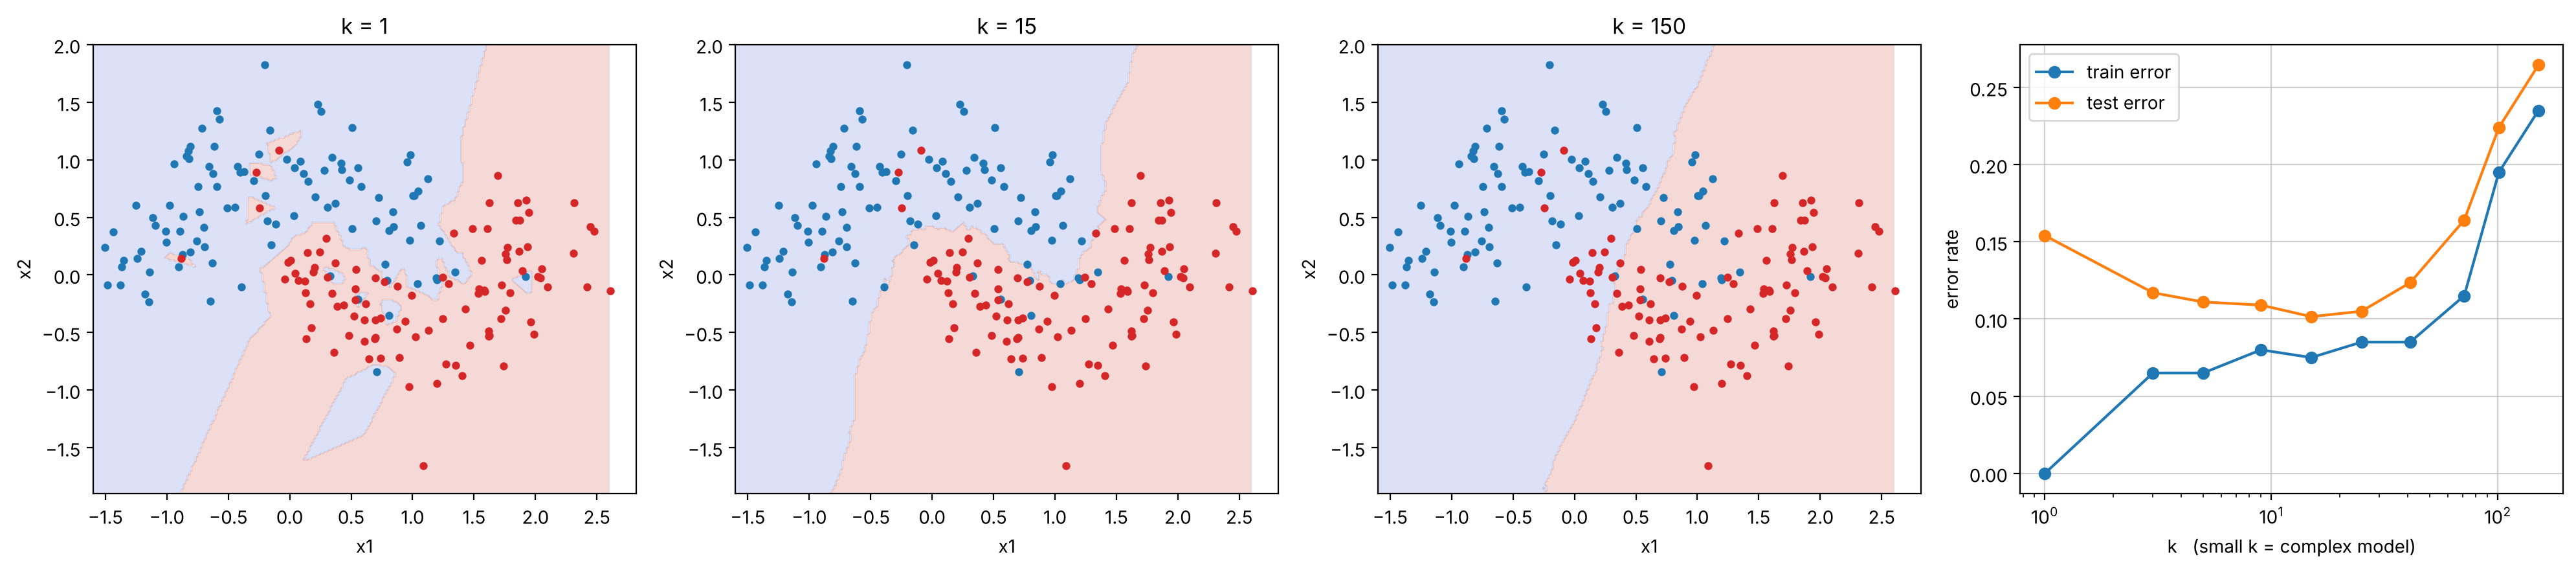

In [3]:
g1, g2 = np.meshgrid(np.linspace(-1.6, 2.6, 250), np.linspace(-1.9, 2.0, 250))
grid = np.column_stack([g1.ravel(), g2.ravel()])

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, k in zip(axes[:3], [1, 15, 150]):
    Z = knn_predict(X_tr, y_tr, grid, k).reshape(g1.shape)
    ax.contourf(g1, g2, Z, alpha=0.2, cmap="coolwarm")
    ax.scatter(X_tr[y_tr == 0, 0], X_tr[y_tr == 0, 1], c="tab:blue", s=12)
    ax.scatter(X_tr[y_tr == 1, 0], X_tr[y_tr == 1, 1], c="tab:red", s=12)
    ax.set_title(f"k = {k}")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

# train and test error as a function of k
ks = [1, 3, 5, 9, 15, 25, 41, 71, 101, 151]
err_tr = [np.mean(knn_predict(X_tr, y_tr, X_tr, k) != y_tr) for k in ks]
err_te = [np.mean(knn_predict(X_tr, y_tr, X_te, k) != y_te) for k in ks]
axes[3].plot(ks, err_tr, "o-", label="train error")
axes[3].plot(ks, err_te, "o-", label="test error")
axes[3].set_xscale("log")
axes[3].set_xlabel("k   (small k = complex model)")
axes[3].set_ylabel("error rate")
axes[3].legend()
axes[3].grid(True, alpha=0.6)
plt.tight_layout()

## 1.4 The Curse of Dimensionality

**The Problem: Local Neighbourhoods Vanish.** In high-dimensional space, the concept of a "local neighbourhood" breaks down. To capture even a small fraction of the data volume, the neighbourhood must stretch to cover a large fraction of the range of each feature.

Suppose the data is uniform in the unit hypercube $[0,1]^d$, and we want a smaller hypercube that contains a fraction $r$ of the data. A cube with side $s$ has volume $s^d$, so:
$$
s^d = r \implies s = r^{1/d}
$$
For $r = 10\%$:
$$
\begin{align*}
d = 1: &\quad s = 0.1^{1/1} = 0.1 = 10\% \\
d = 2: &\quad s = 0.1^{1/2} \approx 31.6\% \\
d = 10: &\quad s = 0.1^{1/10} \approx 79.4\%
\end{align*}
$$
**Implication:** in a 10-dimensional space, our "local" neighbourhood must span nearly 80% of the range of each feature! The neighbours are no longer meaningfully "local".

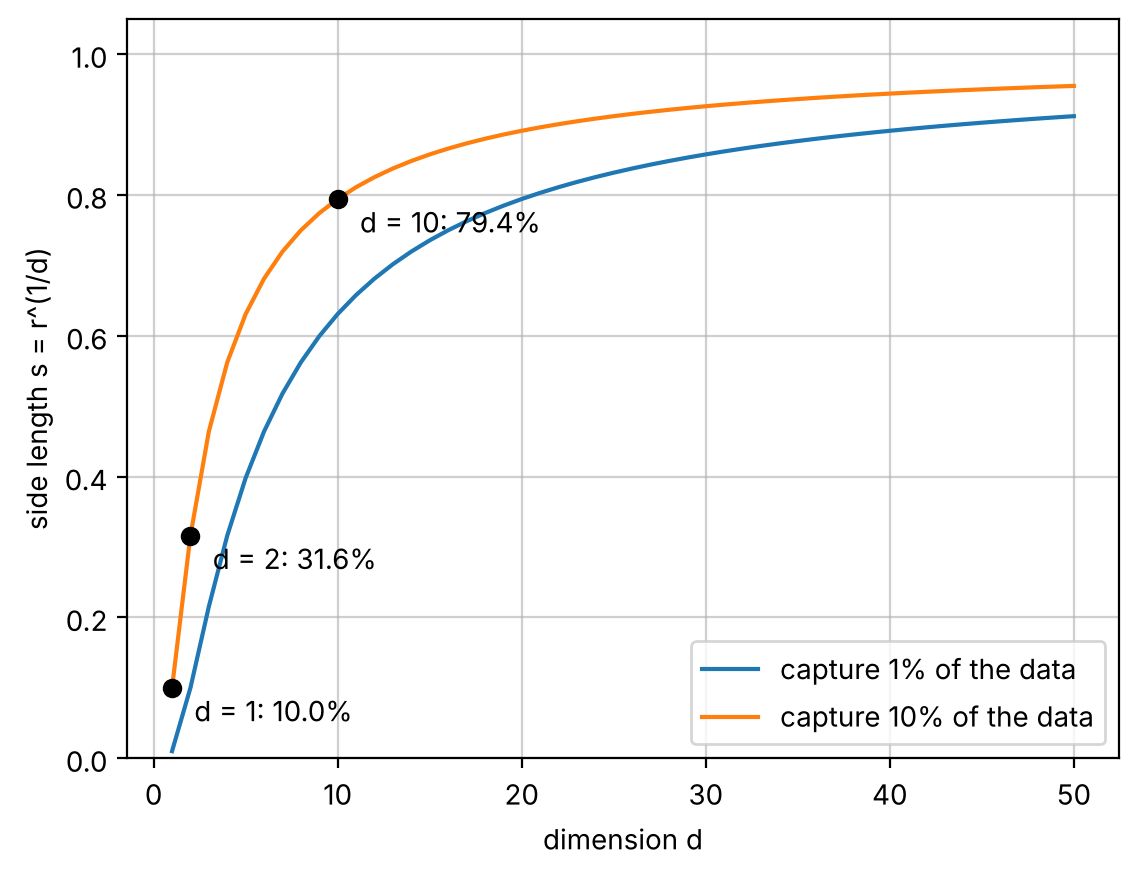

In [4]:
d = np.arange(1, 51)
for r in [0.01, 0.1]:
    plt.plot(d, r**(1/d), label=f"capture {r:.0%} of the data")
for dim in [1, 2, 10]:
    plt.plot(dim, 0.1**(1/dim), "ko")
    plt.annotate(f"d = {dim}: {0.1**(1/dim):.1%}", (dim, 0.1**(1/dim)), textcoords="offset points", xytext=(8, -12))
plt.xlabel("dimension d")
plt.ylabel("side length s = r^(1/d)")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True, alpha=0.6)

Another way to see this is that in high dimensions all points end up roughly the same distance away, so the "nearest" neighbour is barely nearer than the farthest one.

In [5]:
rng = np.random.default_rng(1)
print(f"{'d':<6} {'nearest / farthest distance':<28}")
print("-" * 34)
for dim in [1, 2, 10, 100, 1000]:
    # 1000 uniform points and one query point in the unit hypercube
    X = rng.random((1000, dim))
    q = rng.random(dim)
    dist = np.linalg.norm(X - q, axis=1)
    print(f"{dim:<6} {dist.min() / dist.max():<28.3f}")

d      nearest / farthest distance 
----------------------------------
1      0.000                       
2      0.029                       
10     0.355                       
100    0.735                       
1000   0.885                       


# 2. Parametric vs. Nonparametric Models

## 2.1 Revisiting Model Assumptions

**Parametric Models** (e.g. linear and logistic regression)
* Assume a fixed functional form.
* The model is defined by a small, fixed number of parameters.
* **Pro:** fast, efficient, and less prone to overfitting if the assumptions are right.
* **Con:** high bias (underfitting) if the assumptions are wrong.

**Nonparametric Models** (e.g. kNN, decision trees)
* Do not assume a fixed functional form.
* Model complexity grows with the size of the dataset (kNN stores all $N$ points, and a tree can grow more leaves when there is more data).
* **Pro:** highly flexible, can fit complex patterns. Low bias.
* **Con:** slower, needs more data, and a high risk of overfitting (high variance).

This is the bias-variance tradeoff from Week 2 again.

# 3. Decision Trees

## 3.1 Hierarchical Questions

Decision trees are also called **Classification And Regression Trees (CART)**. They are models that make predictions by asking a series of simple questions about the features.

The idea is to recursively partition the feature space into disjoint regions, and assign a simple model (like a constant class label) to each region. For example:
```
                x1 <= 3 ?
               /         \
            yes           no
             /             \
        x2 <= 2 ?        Class A
         /      \
       yes       no
       /          \
   Class A      Class B
```
We can write the tree as:
$$
f(x) = \sum_{\ell=1}^{L}c_\ell\,\mathbb{1}[x \in R_\ell]
$$
Where:
$$\begin{align}
    &R_\ell \text{: is the region of feature space that ends up in leaf } \ell \\
    &c_\ell \text{: is the prediction in that leaf (the majority class of the training points in } R_\ell\text{)}
\end{align}
$$

## 3.2 Visualising Tree Partitions

Each split corresponds to an **axis-aligned cut** in the feature space. The tree above cuts at $x_1 = 3$ first, then cuts the left half at $x_2 = 2$.

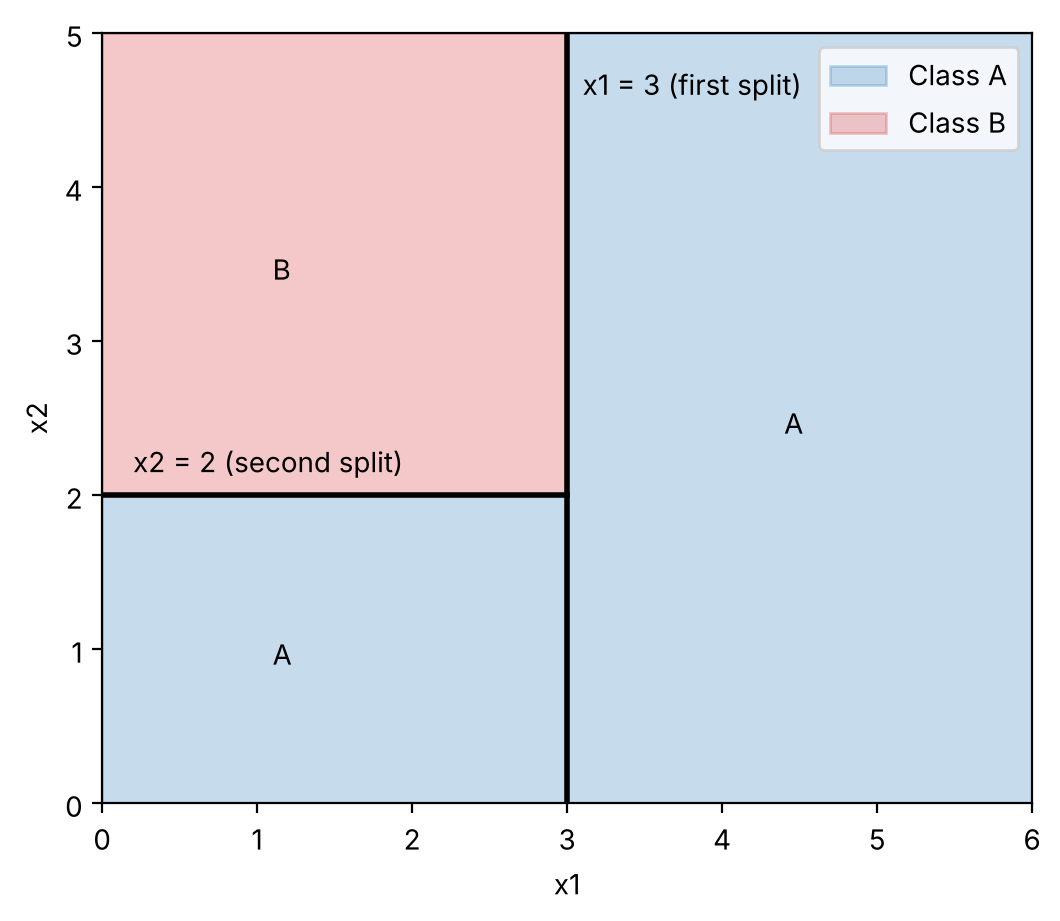

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))

# the three regions of the example tree
ax.fill_between([0, 3], 0, 2, color="tab:blue", alpha=0.25, label="Class A")
ax.fill_between([3, 6], 0, 5, color="tab:blue", alpha=0.25)
ax.fill_between([0, 3], 2, 5, color="tab:red", alpha=0.25, label="Class B")

# the two cuts
ax.axvline(3, color="black", linewidth=2)
ax.plot([0, 3], [2, 2], color="black", linewidth=2)
ax.text(3.1, 4.6, "x1 = 3 (first split)")
ax.text(0.2, 2.15, "x2 = 2 (second split)")
ax.text(1.1, 0.9, "A")
ax.text(1.1, 3.4, "B")
ax.text(4.4, 2.4, "A")

ax.set_xlim(0, 6)
ax.set_ylim(0, 5)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.legend(loc="upper right")

## 3.3 How to Build a Tree: Recursive Splitting

Trees are built top-down using a **greedy** algorithm like CART:
1. Start with all data in the root node.
2. Find the best possible split $(j,t)$ across all features $j$ and all thresholds $t$. "Best" means the split that results in the "purest" child nodes.
3. Create two child nodes and move the data into them based on the split: $x_j \leq t$ goes left, $x_j > t$ goes right.
4. Repeat this process on each child node recursively.
5. Stop when a node is perfectly pure, contains too few samples, or a max depth is reached.

It is greedy because it picks the best split right now, without looking ahead to see whether a worse split now would allow better splits later.

## 3.4 Measuring Node Impurity

We want to choose the split that maximally reduces **impurity**. For a region with class proportions $p_c$ (the fraction of points in the node with class $c$), two common measures are:

**Gini Impurity:**
$$
I_G = 1 - \sum_{c}p_c^2
$$
**Entropy:**
$$
I_H = -\sum_{c}p_c\log_2(p_c)
$$
(with $0\log_2 0 = 0$). Both are $0$ for a pure node and maximised for a uniform distribution.

### For 2 classes
Let $p = p_1$, so $p_0 = 1 - p$:
$$
\begin{align*}
I_G &= 1 - p^2 - (1-p)^2 = 2p(1-p) \\
I_H &= -p\log_2 p - (1-p)\log_2(1-p)
\end{align*}
$$
Taking the derivative of the Gini impurity and setting it to zero:
$$
\frac{dI_G}{dp} = 2 - 4p = 0 \implies p = 0.5, \quad I_G = 2(0.5)(0.5) = 0.5
$$
And for entropy, $\frac{dI_H}{dp} = \log_2\frac{1-p}{p} = 0 \implies p = 0.5$, with $I_H = 1$ bit. So both are largest when the two classes are mixed 50/50, and $0$ when $p = 0$ or $p = 1$ (a pure node).

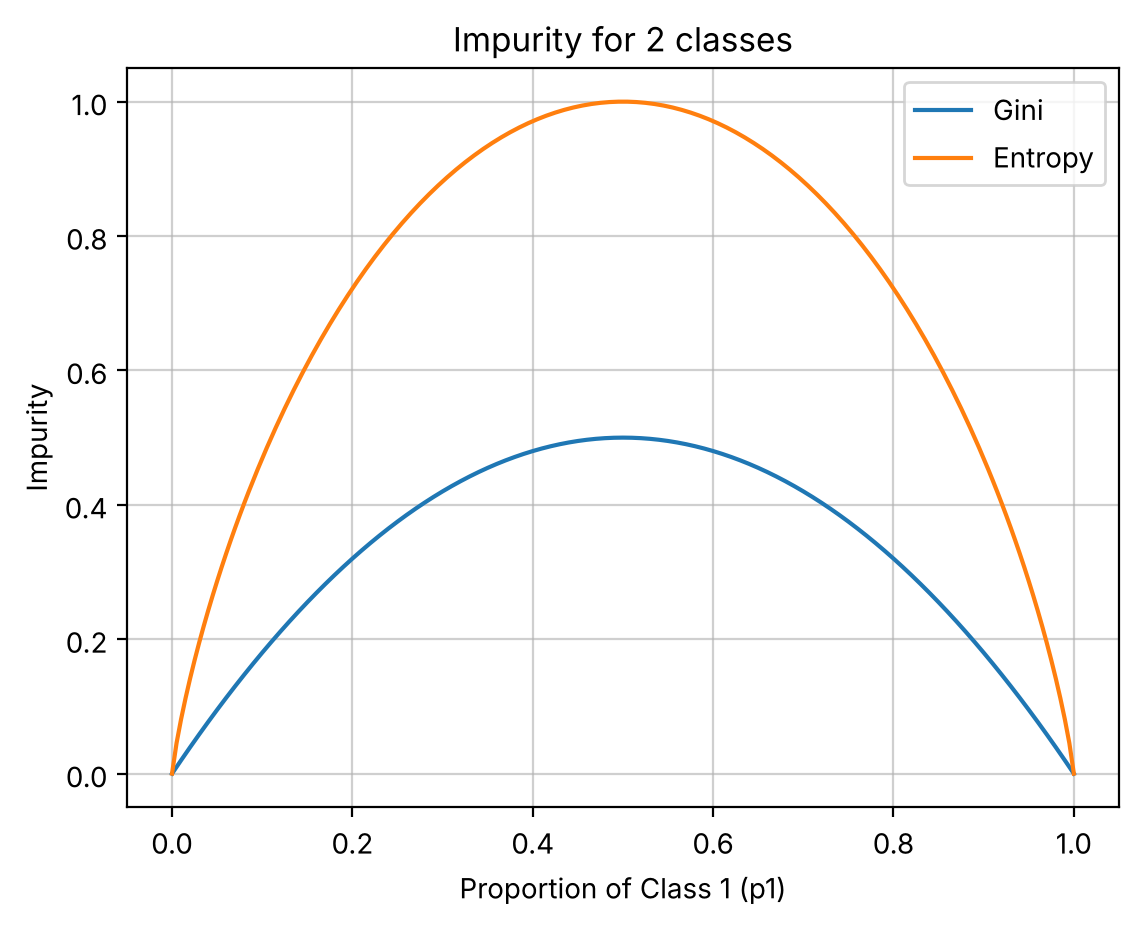

In [7]:
def gini(p):
    # p is a vector of class proportions
    return 1 - np.sum(p**2)

def entropy(p):
    p = p[p > 0]   # 0 log 0 = 0
    return -np.sum(p*np.log2(p))

p1 = np.linspace(0, 1, 201)
plt.plot(p1, [gini(np.array([p, 1-p])) for p in p1], label="Gini")
plt.plot(p1, [entropy(np.array([p, 1-p])) for p in p1], label="Entropy")
plt.xlabel("Proportion of Class 1 (p1)")
plt.ylabel("Impurity")
plt.title("Impurity for 2 classes")
plt.legend()
plt.grid(True, alpha=0.6)

## 3.5 Choosing the Best Split

A split $(j,t)$ sends $N_L$ of the node's $N$ points left and $N_R$ right. The impurity of the children is the weighted average, and the **impurity reduction** (or **information gain** when using entropy) is:
$$
\Delta I(j,t) = I(\text{parent}) - \left[\frac{N_L}{N}I(\text{left}) + \frac{N_R}{N}I(\text{right})\right]
$$
The best split is $(j^*,t^*) = \arg\max_{j,t}\Delta I(j,t)$. We only need to try thresholds halfway between consecutive sorted values of $x_j$, since any $t$ between the same two points gives the same split.

### Worked Example
A node has 10 points: 5 of class A and 5 of class B, so $I_G(\text{parent}) = 1 - 0.5^2 - 0.5^2 = 0.5$.
* **Split 1** gives left = (4 A, 1 B) and right = (1 A, 4 B):
$$
I_G(\text{left}) = I_G(\text{right}) = 1 - 0.8^2 - 0.2^2 = 0.32 \implies \Delta I = 0.5 - \left[\tfrac{5}{10}(0.32) + \tfrac{5}{10}(0.32)\right] = 0.18
$$
* **Split 2** gives left = (5 A, 3 B) and right = (0 A, 2 B):
$$
I_G(\text{left}) = 1 - 0.625^2 - 0.375^2 = 0.469, \; I_G(\text{right}) = 0 \implies \Delta I = 0.5 - \left[\tfrac{8}{10}(0.469) + \tfrac{2}{10}(0)\right] = 0.125
$$
So we pick Split 1, even though Split 2 creates a perfectly pure node, because Split 1 makes the most progress overall.

In [8]:
def impurity_reduction(parent, left, right, measure=gini):
    # each argument is a vector of class counts
    N, NL, NR = parent.sum(), left.sum(), right.sum()
    return measure(parent/N) - (NL/N*measure(left/NL) + NR/N*measure(right/NR))

parent = np.array([5, 5])
print(f"Split 1: Delta I = {impurity_reduction(parent, np.array([4, 1]), np.array([1, 4])):.3f}")
print(f"Split 2: Delta I = {impurity_reduction(parent, np.array([5, 3]), np.array([0, 2])):.3f}")

Split 1: Delta I = 0.180
Split 2: Delta I = 0.125


## 3.6 Building a Decision Tree in Python

Now we implement CART from scratch. The `max_features` argument is not needed for a normal tree, but we will use it for Random Forests in Section 5, and the `importances` it records will be used for MDI in Section 6.

To find the best threshold for feature $j$ quickly, we sort the node's points by $x_j$, then use cumulative class counts, so the class counts of every possible left child come from a single pass.

In [9]:
class DecisionTree:
    def __init__(self, max_depth=None, min_samples_leaf=1, max_features=None, seed=0):
        self.max_depth = max_depth if max_depth is not None else np.inf
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features        # m < D features per split (Random Forest), None = all D
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):
        self.n_classes = y.max() + 1
        self.n_total = len(y)
        self.importances = np.zeros(X.shape[1])   # MDI, filled in as we split
        self.root = self._grow(X, y, depth=0)
        if self.importances.sum() > 0:
            self.importances /= self.importances.sum()
        return self

    def _best_split(self, X, y):
        N, D = X.shape
        counts_parent = np.bincount(y, minlength=self.n_classes)
        best = (0.0, None, None)                  # (impurity reduction, feature, threshold)

        # first we pick which features we are allowed to look at
        features = np.arange(D)
        if self.max_features is not None:
            features = self.rng.choice(D, self.max_features, replace=False)

        for j in features:
            order = np.argsort(X[:, j])
            xs, ys = X[order, j], y[order]
            # cumulative class counts: row i = class counts of the first i+1 points (the left child)
            left = np.cumsum(np.eye(self.n_classes)[ys], axis=0)[:-1]
            right = counts_parent - left
            NL = np.arange(1, N)
            NR = N - NL
            gini_L = 1 - np.sum((left / NL[:, None])**2, axis=1)
            gini_R = 1 - np.sum((right / NR[:, None])**2, axis=1)
            gain = gini(counts_parent / N) - (NL/N*gini_L + NR/N*gini_R)

            # only split between two different values, and respect the minimum leaf size
            valid = (xs[1:] > xs[:-1]) & (NL >= self.min_samples_leaf) & (NR >= self.min_samples_leaf)
            if valid.any():
                i = np.argmax(np.where(valid, gain, -np.inf))
                if gain[i] > best[0]:
                    best = (gain[i], j, (xs[i] + xs[i+1]) / 2)
        return best

    def _grow(self, X, y, depth):
        counts = np.bincount(y, minlength=self.n_classes)
        node = {"proba": counts / counts.sum()}

        # stopping rules: pure node, too few samples, or max depth reached
        if counts.max() == len(y) or len(y) < 2*self.min_samples_leaf or depth >= self.max_depth:
            return node

        gain, j, t = self._best_split(X, y)
        if j is None:
            return node

        # MDI: impurity reduction weighted by the fraction of training samples reaching this node
        self.importances[j] += len(y) / self.n_total * gain

        mask = X[:, j] <= t
        node.update(feature=j, threshold=t,
                    left=self._grow(X[mask], y[mask], depth + 1),
                    right=self._grow(X[~mask], y[~mask], depth + 1))
        return node

    def _proba(self, node, X):
        if "feature" not in node:
            return np.tile(node["proba"], (len(X), 1))
        out = np.empty((len(X), self.n_classes))
        mask = X[:, node["feature"]] <= node["threshold"]
        out[mask] = self._proba(node["left"], X[mask])
        out[~mask] = self._proba(node["right"], X[~mask])
        return out

    def predict_proba(self, X):
        return self._proba(self.root, X)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

def print_tree(node, names, depth=0):
    # prints the questions the tree asks, like the diagram in 3.1
    pad = "    " * depth
    if "feature" not in node:
        print(f"{pad}predict class {np.argmax(node['proba'])}  (proportions {np.round(node['proba'], 2)})")
        return
    print(f"{pad}{names[node['feature']]} <= {node['threshold']:.2f} ?")
    print_tree(node["left"], names, depth + 1)
    print_tree(node["right"], names, depth + 1)

In [10]:
# a depth 2 tree on the moons data, small enough to read
tree2 = DecisionTree(max_depth=2).fit(X_tr, y_tr)
print_tree(tree2.root, ["x1", "x2"])
print(f"\nTest accuracy (depth 2): {np.mean(tree2.predict(X_te) == y_te):.3f}")

x1 <= -0.10 ?
    x1 <= -0.28 ?
        predict class 0  (proportions [0.98 0.02])
        predict class 0  (proportions [0.78 0.22])
    x2 <= 0.40 ?
        predict class 1  (proportions [0.14 0.86])
        predict class 0  (proportions [0.76 0.24])

Test accuracy (depth 2): 0.828


## 3.7 Pros and Cons of Decision Trees

* **[+]** Interpretable ("white box"), we can read off the questions as above.
* **[+]** Handles mixed data types and doesn't require feature scaling (a split only depends on the order of the values).
* **[-]** **High Variance:** very prone to overfitting.
* **[-]** The greedy approach may not be globally optimal.

We can see the overfitting by growing deeper and deeper trees:

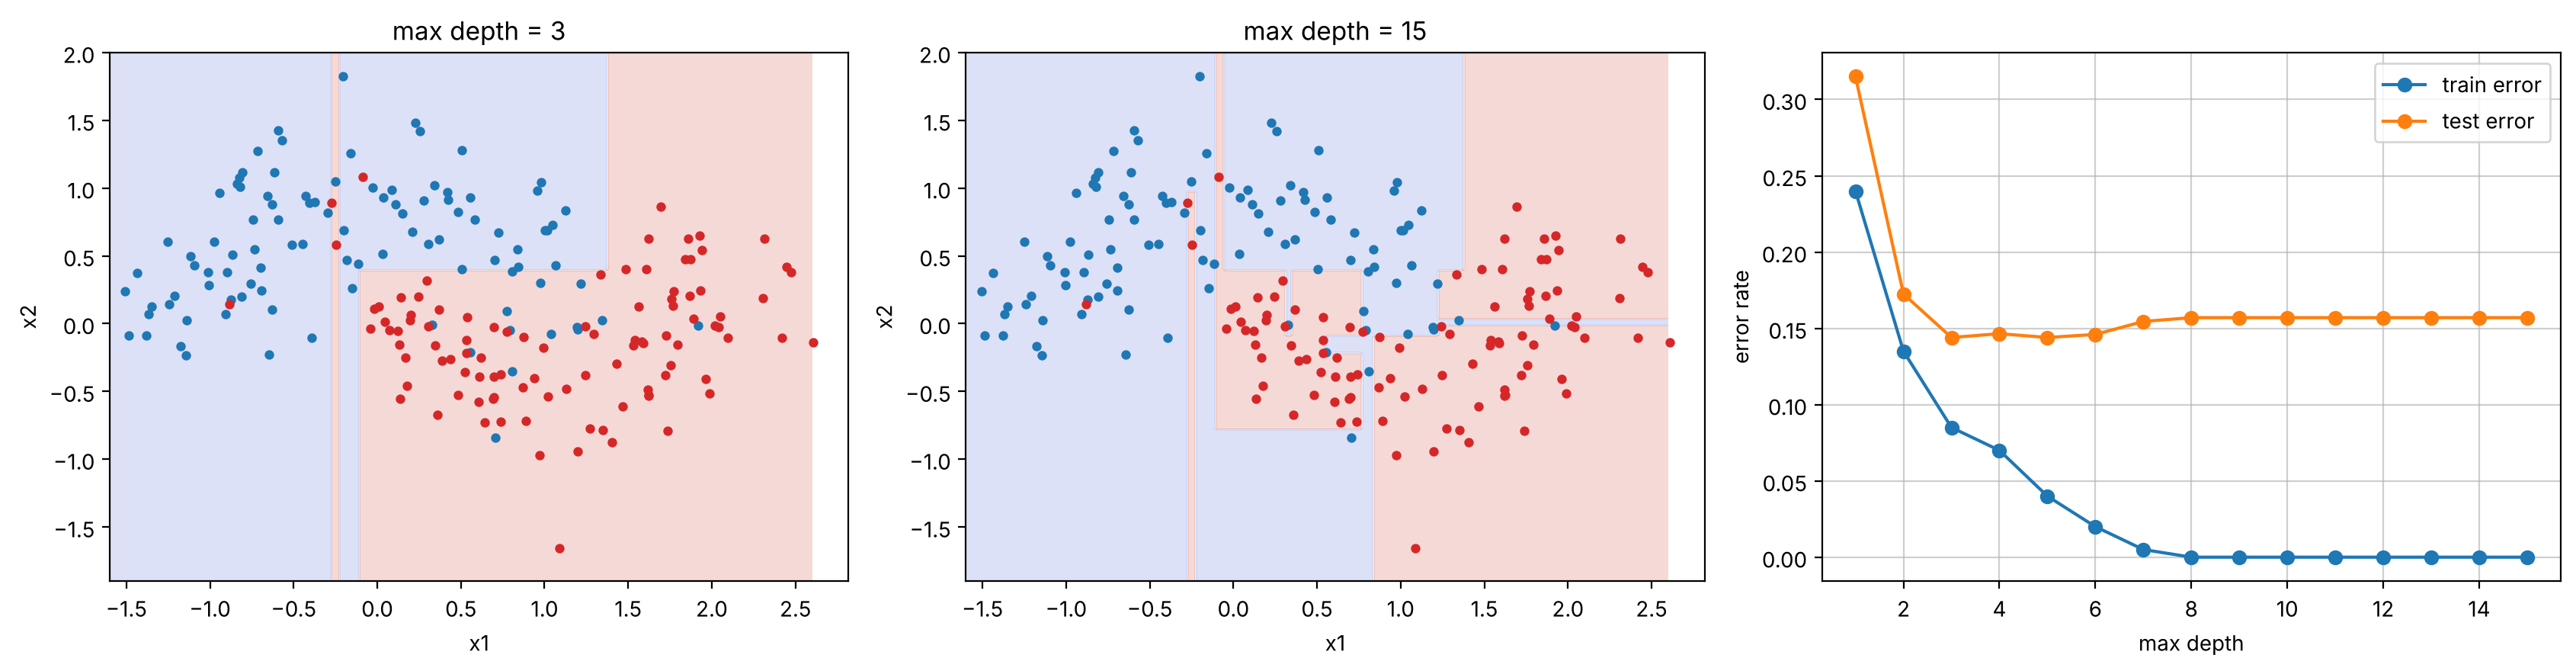

In [11]:
depths = range(1, 16)
trees = {d: DecisionTree(max_depth=d).fit(X_tr, y_tr) for d in depths}
err_tr = [np.mean(trees[d].predict(X_tr) != y_tr) for d in depths]
err_te = [np.mean(trees[d].predict(X_te) != y_te) for d in depths]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, d in zip(axes[:2], [3, 15]):
    Z = trees[d].predict(grid).reshape(g1.shape)
    ax.contourf(g1, g2, Z, alpha=0.2, cmap="coolwarm")
    ax.scatter(X_tr[y_tr == 0, 0], X_tr[y_tr == 0, 1], c="tab:blue", s=12)
    ax.scatter(X_tr[y_tr == 1, 0], X_tr[y_tr == 1, 1], c="tab:red", s=12)
    ax.set_title(f"max depth = {d}")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

axes[2].plot(depths, err_tr, "o-", label="train error")
axes[2].plot(depths, err_te, "o-", label="test error")
axes[2].set_xlabel("max depth")
axes[2].set_ylabel("error rate")
axes[2].legend()
axes[2].grid(True, alpha=0.6)
plt.tight_layout()

The deep tree carves out tiny boxes around individual noisy points: the training error goes to 0 while the test error stops improving and creeps back up. So how can we fix the high variance problem?

# 4. Ensemble Learning and Bagging

## 4.1 The Problem with Single Decision Trees

Decision Trees are very sensitive to the specific training data they see. This is the definition of **high variance**. We can see this by training deep trees on a few different random samples of the same data:

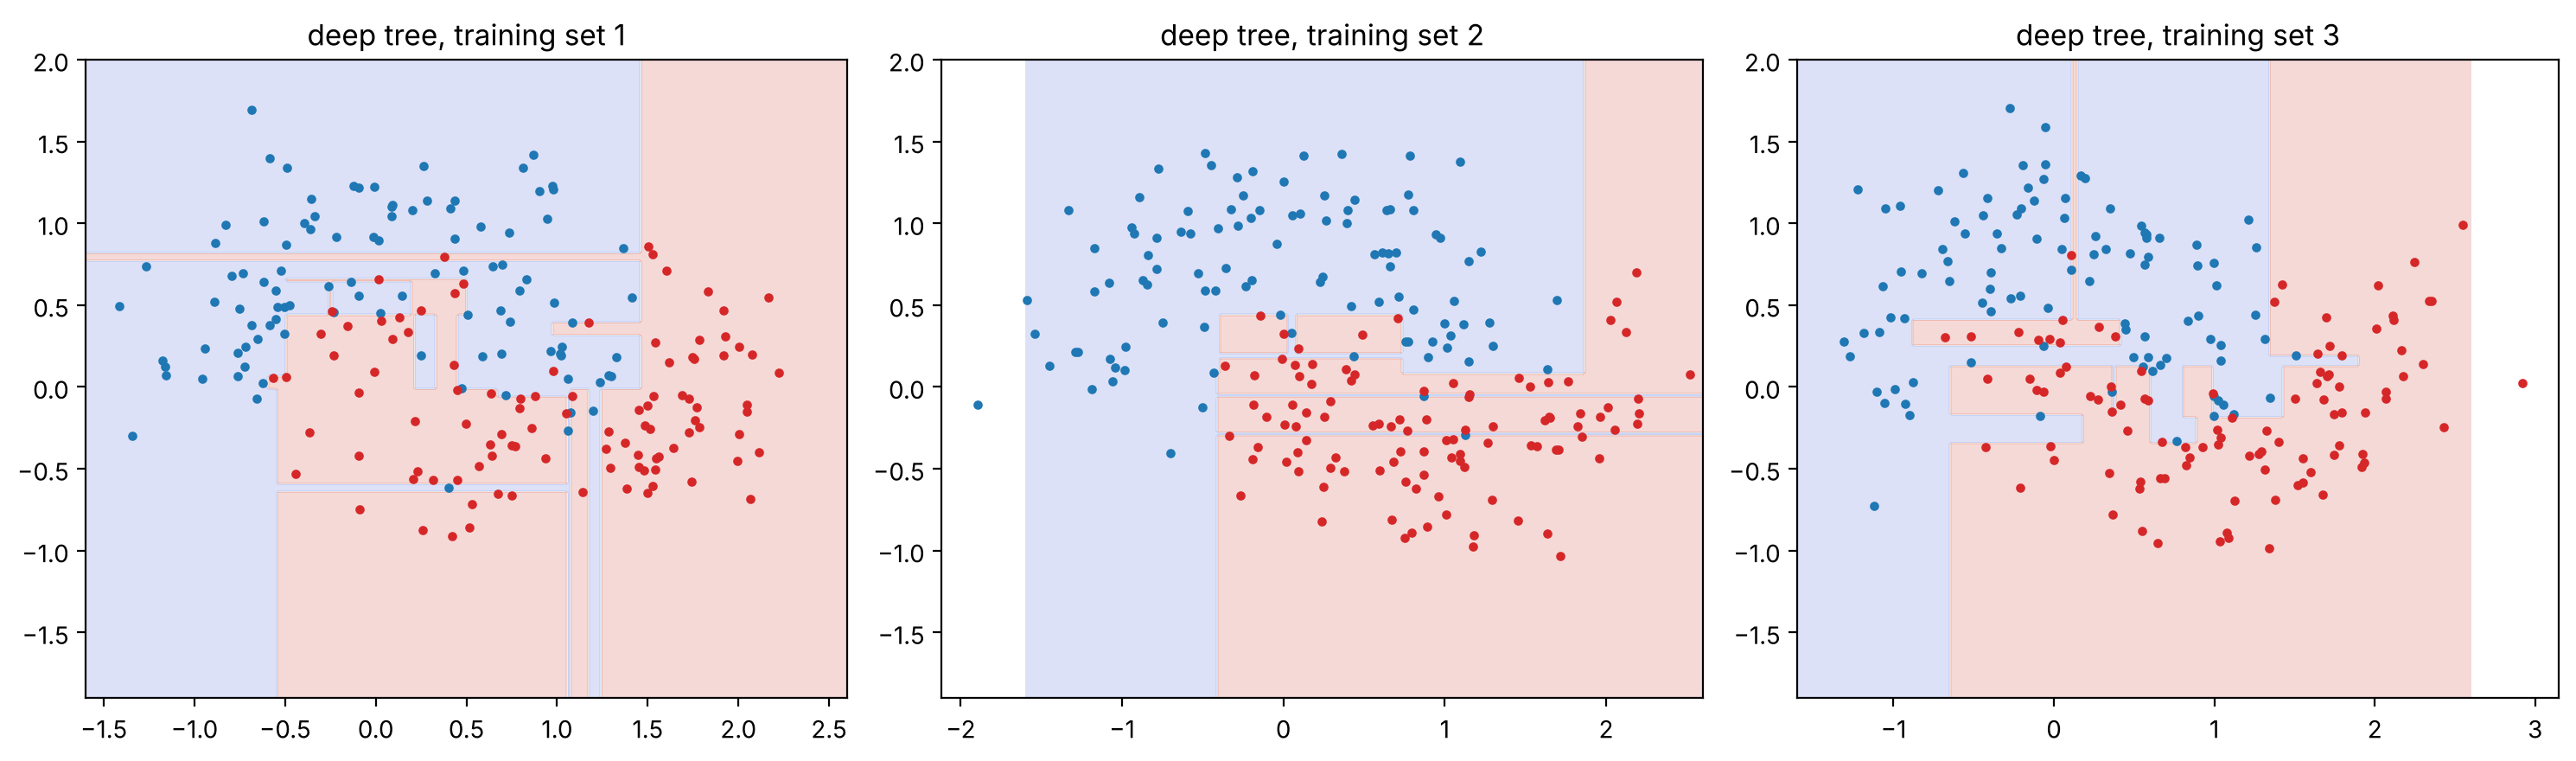

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
rng = np.random.default_rng(2)
for ax, seed in zip(axes, range(3)):
    # a fresh training set drawn from the same distribution each time
    Xs, ys = make_moons(200, noise=0.3, rng=rng)
    t = DecisionTree().fit(Xs, ys)
    ax.contourf(g1, g2, t.predict(grid).reshape(g1.shape), alpha=0.2, cmap="coolwarm")
    ax.scatter(Xs[ys == 0, 0], Xs[ys == 0, 1], c="tab:blue", s=8)
    ax.scatter(Xs[ys == 1, 0], Xs[ys == 1, 1], c="tab:red", s=8)
    ax.set_title(f"deep tree, training set {seed + 1}")
plt.tight_layout()

The three trees disagree a lot. **The Core Idea:** if we average many different, unstable models, can we get one stable, accurate model? This is **ensemble learning**.

## 4.2 Why Averaging Reduces Variance

Suppose we have $B$ models $f_1(x),\dots,f_B(x)$, each with variance $\sigma^2$, and any two of them have correlation $\rho$. The variance of their average is:

### Proof
$$
\begin{align*}
\text{Var}\left(\frac{1}{B}\sum_{b=1}^{B}f_b\right) &= \frac{1}{B^2}\left[\sum_{b=1}^{B}\text{Var}(f_b) + \sum_{b \neq b'}\text{Cov}(f_b,f_{b'})\right] && (\text{variance of a sum}) \\
&= \frac{1}{B^2}\left[B\sigma^2 + B(B-1)\rho\sigma^2\right] && (\text{since Cov}(f_b,f_{b'}) = \rho\sigma^2 \text{ and there are } B(B-1) \text{ pairs}) \\
&= \rho\sigma^2 + \frac{1-\rho}{B}\sigma^2
\end{align*}
$$
* If the models are independent ($\rho = 0$), the variance is $\sigma^2/B$, which goes to $0$ as $B$ grows.
* If they are correlated ($\rho > 0$), the first term $\rho\sigma^2$ does not go away however many models we add.

So averaging helps, and it helps more the **less correlated** the models are. This is exactly what Random Forests improve on (Section 5).

## 4.3 Bagging: Bootstrap Aggregating

**Bagging** = **B**ootstrap **Agg**regat**ing** is a general technique to reduce the variance of any high-variance model.
* **Bootstrap:** create $B$ new datasets by sampling **with replacement** from the original data.
* **Train:** train one base model $f_b(x)$ (e.g. a deep decision tree) on each bootstrap sample.
* **Aggregate:** the final prediction is the majority vote (classification) or average (regression) of all $B$ models:
$$
\hat{f}_{bag}(x) = \text{majority vote}\{f_1(x),\dots,f_B(x)\} \quad \text{or} \quad \hat{f}_{bag}(x) = \frac{1}{B}\sum_{b=1}^{B}f_b(x)
$$

The name comes from "pull oneself up by one's bootstraps": we are trying to "lift" our statistical estimates from the sample data alone, without any outside help.

### Sampling with replacement
Each bootstrap sample has the same size as the original. Due to sampling with replacement, some points are duplicated while others are omitted entirely.

In [13]:
rng = np.random.default_rng(3)
N = 10
boot = rng.choice(N, size=N, replace=True)
print(f"original indices : {np.arange(N)}")
print(f"bootstrap sample : {np.sort(boot)}")
print(f"left out         : {np.setdiff1d(np.arange(N), boot)}\n")

# for a large dataset, what fraction of the points appear at least once?
N = 100000
boot = rng.choice(N, size=N, replace=True)
print(f"N = {N}: fraction of points in the bootstrap sample = {len(np.unique(boot)) / N:.3f}")

original indices : [0 1 2 3 4 5 6 7 8 9]
bootstrap sample : [0 0 0 1 1 2 5 8 8 8]
left out         : [3 4 6 7 9]

N = 100000: fraction of points in the bootstrap sample = 0.631


About 63% of the points appear in each bootstrap sample, and about 37% are left out. We will see why in Section 5.2.

## 4.4 Bagging in Python

In [14]:
class RandomForest:
    # bagging is the special case max_features = None (every split looks at all D features)
    def __init__(self, n_trees=100, max_features=None, max_depth=None, min_samples_leaf=1, seed=0):
        self.n_trees = n_trees
        self.max_features = max_features
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.seed = seed

    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        N = len(y)
        self.n_classes = y.max() + 1
        self.trees, self.in_bag = [], []
        for b in range(self.n_trees):
            # first we draw a bootstrap sample
            idx = rng.choice(N, size=N, replace=True)
            # next we grow a deep tree on it
            tree = DecisionTree(max_depth=self.max_depth, min_samples_leaf=self.min_samples_leaf,
                                max_features=self.max_features, seed=rng.integers(1e9))
            self.trees.append(tree.fit(X[idx], y[idx]))
            # we remember which points each tree saw, for the OOB error later
            in_bag = np.zeros(N, dtype=bool)
            in_bag[idx] = True
            self.in_bag.append(in_bag)
        self.in_bag = np.array(self.in_bag)          # n_trees x N
        return self

    def predict(self, X, n_trees=None):
        # majority vote of the (first n_trees) trees
        trees = self.trees[:n_trees]
        votes = np.array([t.predict(X) for t in trees])
        counts = np.array([(votes == c).sum(axis=0) for c in range(self.n_classes)])
        return np.argmax(counts, axis=0)

    @property
    def feature_importances(self):
        # MDI: average of each tree's (normalised) impurity reductions
        return np.mean([t.importances for t in self.trees], axis=0)

Single deep tree : test accuracy = 0.843
Bagging (B = 100): test accuracy = 0.877


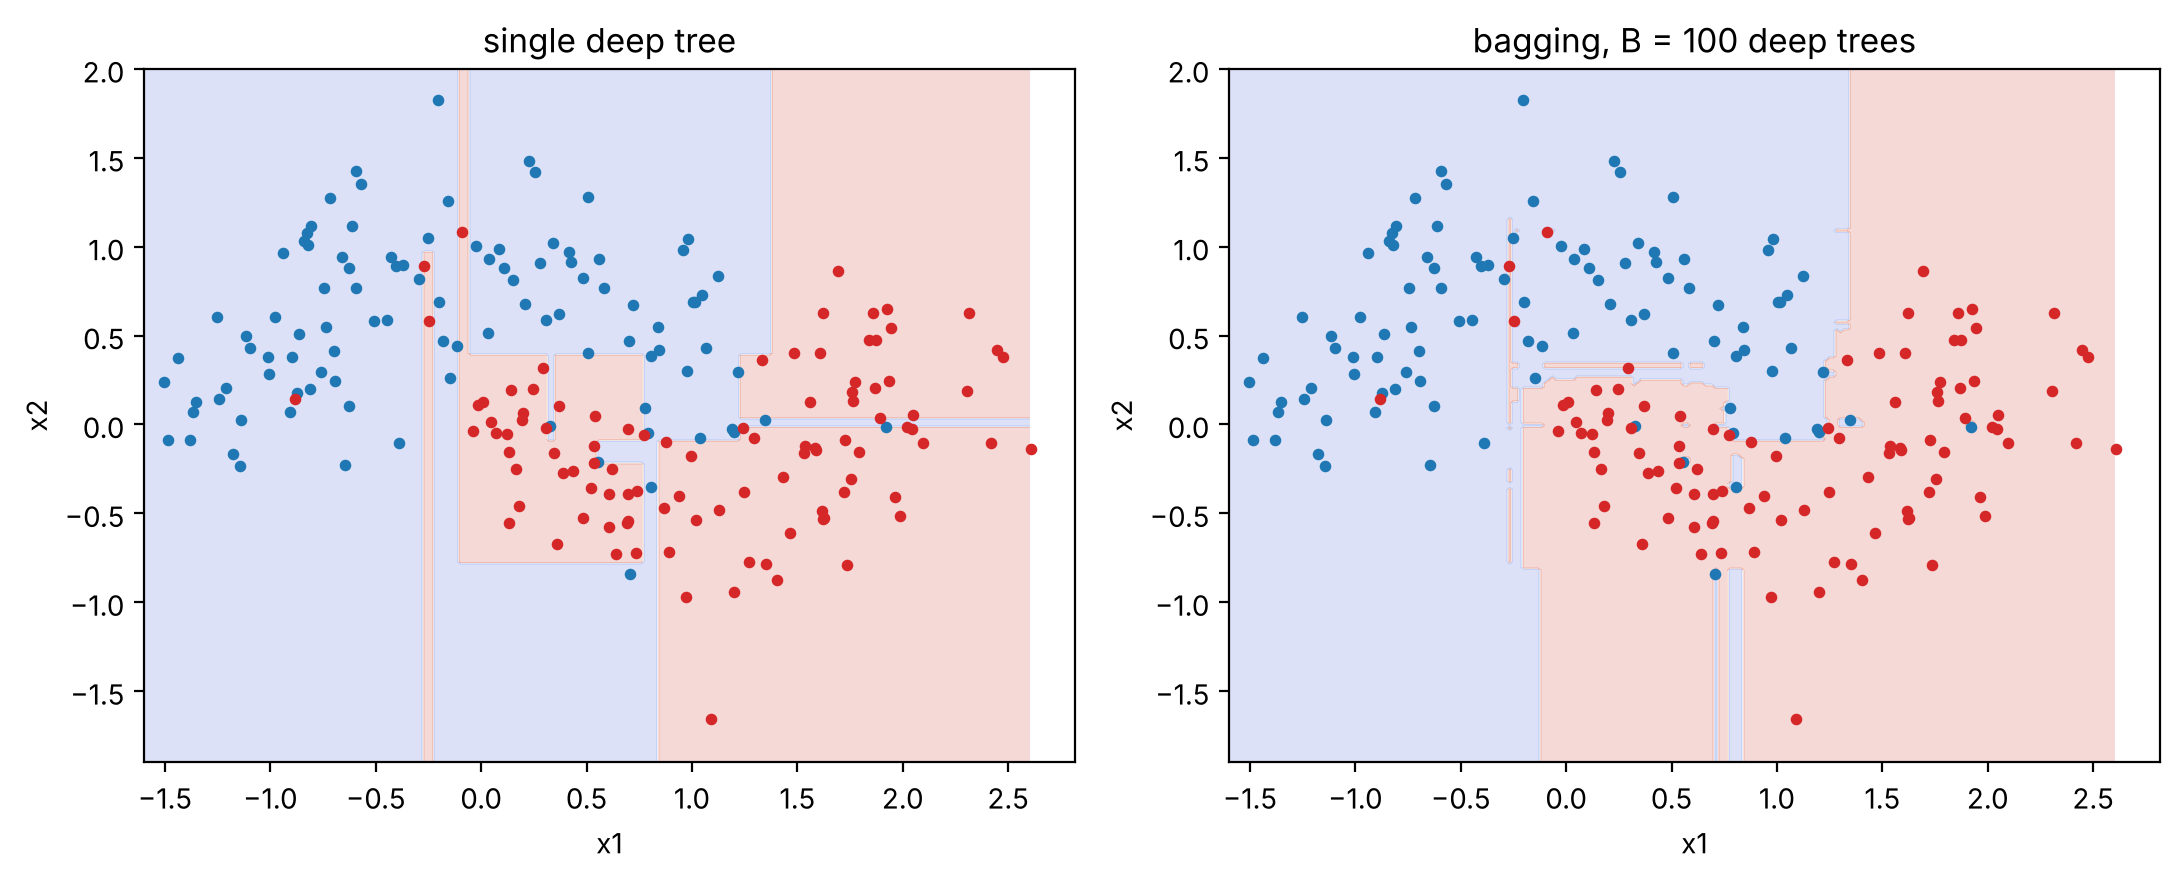

In [15]:
single = DecisionTree().fit(X_tr, y_tr)
bag = RandomForest(n_trees=100, max_features=None).fit(X_tr, y_tr)

print(f"Single deep tree : test accuracy = {np.mean(single.predict(X_te) == y_te):.3f}")
print(f"Bagging (B = 100): test accuracy = {np.mean(bag.predict(X_te) == y_te):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, model, name in [(axes[0], single, "single deep tree"), (axes[1], bag, "bagging, B = 100 deep trees")]:
    ax.contourf(g1, g2, model.predict(grid).reshape(g1.shape), alpha=0.2, cmap="coolwarm")
    ax.scatter(X_tr[y_tr == 0, 0], X_tr[y_tr == 0, 1], c="tab:blue", s=10)
    ax.scatter(X_tr[y_tr == 1, 0], X_tr[y_tr == 1, 1], c="tab:red", s=10)
    ax.set_title(name)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
plt.tight_layout()

Each tree in the bag is still deep (low bias), but the vote smooths out their individual quirks, so the boundary is much more stable.

# 5. Random Forests and Out-of-Bag Error

## 5.1 Random Forests: Bagging with Feature Subsampling

Random Forests improve on Bagging by further **decorrelating** the trees.

### The Random Forest Algorithm
1. Create $B$ bootstrap samples of the data (like Bagging).
2. For each sample, grow a decision tree.
3. **Key Difference:** at each node, do not search all $D$ features for the best split. Instead, randomly select a small subset of $m < D$ features and find the best split only among those features (a common default for classification is $m \approx \sqrt{D}$).
4. Aggregate predictions by majority vote.

**Why it helps:** this forces the trees to be more diverse. Even if one feature is very powerful, it won't be selected for every split in every tree, giving other features a chance. More diversity means a smaller correlation $\rho$, and from Section 4.2 that means a lower variance for the ensemble.

## 5.2 Out-of-Bag (OOB) Error: What is it?

When creating a bootstrap sample of size $N$ from data of size $N$:
* The probability of a specific data point not being picked in a single draw is $(1 - 1/N)$.
* The draws are independent, so the probability of it not being picked in any of the $N$ draws is $(1 - 1/N)^N$.

### Proof that $(1 - 1/N)^N \to e^{-1}$
$$
\begin{align*}
\log\left(1 - \frac{1}{N}\right)^N &= N\log\left(1 - \frac{1}{N}\right) \\
&= N\left(-\frac{1}{N} - \frac{1}{2N^2} - \frac{1}{3N^3} - \dots\right) && (\text{Taylor series } \log(1-u) = -u - \tfrac{u^2}{2} - \tfrac{u^3}{3} - \dots) \\
&= -1 - \frac{1}{2N} - \frac{1}{3N^2} - \dots \\
&\to -1 \text{ as } N \to \infty
\end{align*}
$$
So:
$$
\lim_{N\to\infty}\left(1 - \frac{1}{N}\right)^N = e^{-1} \approx 0.368
$$
This means for any given tree in the forest, about **37%** of the original data points were left out of its training set. These are its **Out-of-Bag (OOB)** samples.

In [16]:
for N in [5, 10, 100, 1000, 100000]:
    print(f"N = {N:<7} (1 - 1/N)^N = {(1 - 1/N)**N:.4f}")
print(f"{'limit':<11} e^-1       = {np.exp(-1):.4f}")

N = 5       (1 - 1/N)^N = 0.3277
N = 10      (1 - 1/N)^N = 0.3487
N = 100     (1 - 1/N)^N = 0.3660
N = 1000    (1 - 1/N)^N = 0.3677
N = 100000  (1 - 1/N)^N = 0.3679
limit       e^-1       = 0.3679


## 5.3 Using OOB Error for Model Evaluation

The OOB samples give a "free" estimate of test error, with no separate validation set or cross-validation.

### The OOB Evaluation Algorithm
1. For each data point $i$ in the original training set:
    * Find the trees that did not use point $i$ in training (its OOB trees).
    * Let this sub-ensemble of OOB trees make a prediction for point $i$.
2. The OOB error is the total number of incorrect predictions made this way, divided by $N$:
$$
\text{OOB error} = \frac{1}{N}\sum_{i=1}^{N}\mathbb{1}\left[\hat{y}_{OOB}(x_i) \neq y_i\right]
$$

**A key advantage:** OOB error is a nearly unbiased estimate of test error once the forest has enough trees. With only a few trees it runs high, since each point is predicted by just $\approx 37\%$ of them.

## 5.4 Random Forests and OOB Error in Python

In [17]:
def oob_error(forest, X, y, n_trees=None):
    n_trees = n_trees or forest.n_trees
    N = len(y)
    counts = np.zeros((N, forest.n_classes))
    for tree, in_bag in zip(forest.trees[:n_trees], forest.in_bag[:n_trees]):
        oob = ~in_bag
        # this tree only votes for the points it did not see in training
        counts[oob, tree.predict(X[oob])] += 1
    has_vote = counts.sum(axis=1) > 0           # with very few trees, some points have no OOB tree yet
    pred = np.argmax(counts, axis=1)
    return np.mean(pred[has_vote] != y[has_vote])

To see the difference between Bagging and Random Forests, we need more than 2 features. We make a dataset with $D = 10$ features, where the class depends on the first 4 features (with the first one being the strongest), and the other 6 are pure noise.

In [18]:
rng = np.random.default_rng(4)

def make_data(n):
    X = rng.normal(size=(n, 10))
    # the signal: x0 matters most, x1, x2, x3 matter less, x4..x9 are noise
    logit = 2.0*X[:, 0] + 1.0*X[:, 1] + 1.0*X[:, 2]*X[:, 3]
    y = (logit + rng.normal(0, 1, n) > 0).astype(int)
    return X, y

X10_tr, y10_tr = make_data(400)
X10_te, y10_te = make_data(4000)

# first we fit the three models
tree10 = DecisionTree(seed=0).fit(X10_tr, y10_tr)
bag10  = RandomForest(n_trees=200, max_features=None, seed=0).fit(X10_tr, y10_tr)
rf10   = RandomForest(n_trees=200, max_features=3, seed=0).fit(X10_tr, y10_tr)     # m = 3 ~ sqrt(10)

print(f"{'model':<28} {'test error':<12} {'OOB error':<10}")
print("-" * 50)
print(f"{'Single deep tree':<28} {np.mean(tree10.predict(X10_te) != y10_te):<12.3f} {'-':<10}")
print(f"{'Bagging (m = D = 10)':<28} {np.mean(bag10.predict(X10_te) != y10_te):<12.3f} {oob_error(bag10, X10_tr, y10_tr):<10.3f}")
print(f"{'Random Forest (m = 3)':<28} {np.mean(rf10.predict(X10_te) != y10_te):<12.3f} {oob_error(rf10, X10_tr, y10_tr):<10.3f}")

model                        test error   OOB error 
--------------------------------------------------
Single deep tree             0.251        -         
Bagging (m = D = 10)         0.197        0.160     


Random Forest (m = 3)        0.185        0.150     


We can also check that the trees in the Random Forest really are less correlated, by measuring how often two trees make the same prediction on the test set:

In [19]:
def mean_agreement(forest, X, n_pairs=300, seed=0):
    rng = np.random.default_rng(seed)
    preds = np.array([t.predict(X) for t in forest.trees])
    pairs = [rng.choice(len(preds), 2, replace=False) for _ in range(n_pairs)]
    return np.mean([np.mean(preds[a] == preds[b]) for a, b in pairs])

print(f"Average agreement between two trees -> Bagging: {mean_agreement(bag10, X10_te):.3f}, Random Forest: {mean_agreement(rf10, X10_te):.3f}")

Average agreement between two trees -> Bagging: 0.785, Random Forest: 0.700


Now we plot the OOB error and the test error as the number of trees grows.

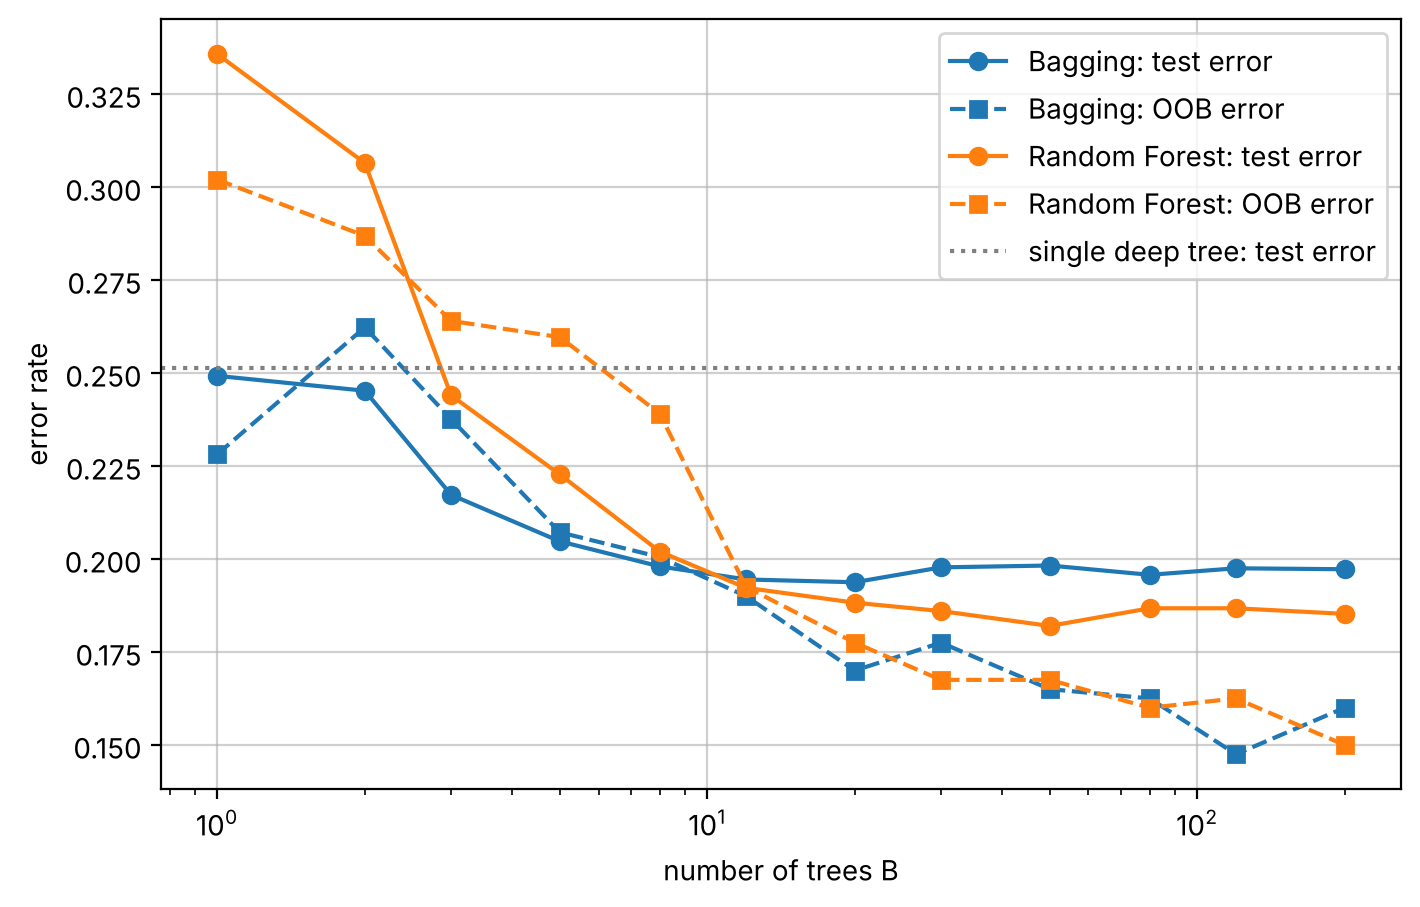

In [20]:
n_list = [1, 2, 3, 5, 8, 12, 20, 30, 50, 80, 120, 200]

fig, ax = plt.subplots(figsize=(8, 5))
for forest, name in [(bag10, "Bagging"), (rf10, "Random Forest")]:
    test = [np.mean(forest.predict(X10_te, n) != y10_te) for n in n_list]
    oob = [oob_error(forest, X10_tr, y10_tr, n) for n in n_list]
    line, = ax.plot(n_list, test, "o-", label=f"{name}: test error")
    ax.plot(n_list, oob, "s--", color=line.get_color(), label=f"{name}: OOB error")

ax.axhline(np.mean(tree10.predict(X10_te) != y10_te), color="gray", linestyle=":", label="single deep tree: test error")
ax.set_xscale("log")
ax.set_xlabel("number of trees B")
ax.set_ylabel("error rate")
ax.legend()
ax.grid(True, alpha=0.6)

With only a few trees the OOB error runs high (each point is only judged by about 37% of the trees). Once $B$ is large it flattens out like the test error, and it ranks the models the same way, without us ever touching the test set. (Here it sits a little below the test error, because it is estimated from only 400 training points, so it has some sampling noise of its own.)

# 6. Feature Importance and Attribution

## 6.1 Feature Importance in General: Attribution

**Attribution** asks how much each input feature contributed to a prediction.
* **Linear models:** the weights are the attribution. $\partial\hat{y}/\partial x_j = w_j$ exactly, so $|w_j|$ ranks the features (if the features are on the same scale).
* **Black boxes:** we use the local linear approximation (a first-order Taylor expansion):
$$
f(x + \delta) \approx f(x) + \nabla f(x)^T\delta
$$
which suggests the attribution:
$$
a_j(x) = \frac{\partial f(x)}{\partial x_j} \quad \text{or} \quad x_j\frac{\partial f(x)}{\partial x_j}
$$
This measures how far the prediction moves when $x_j$ is nudged. For a linear $f$ this returns $w_j$, but now it is one number per **prediction**, not per model.

A forest is piecewise constant, so $\nabla_xf = 0$ almost everywhere. Hence the two methods that follow.

Random Forests are powerful, but can seem like a black box. Feature importance helps us understand which features are most influential for making predictions:
* Which features are the most predictive?
* Can we simplify our model by using fewer features?

Two common methods for calculating feature importance in tree ensembles are **Mean Decrease in Impurity (MDI)** and **Permutation Importance** (or Mean Decrease in Accuracy).

## 6.2 Method 1: Mean Decrease in Impurity (MDI)

A feature's importance is measured by how much it helps to "purify" the nodes in the trees. This is based on the impurity measures (Gini, Entropy) we use to build the trees.
1. **For a single tree:** the importance of a feature is the sum of the impurity reductions at all nodes where that feature was used to split, each weighted by the fraction of training samples reaching that node.
2. **For the forest:** the importance score is the average of the feature's importance scores across all trees in the forest.

$$
\text{MDI}(j) = \frac{1}{B}\sum_{b=1}^{B}\sum_{\substack{\text{nodes } v \text{ in tree } b \\ \text{split on } j}}\frac{N_v}{N}\Delta I(v)
$$
Where:
$$\begin{align}
    &N_v/N \text{: is the fraction of training samples that reach node } v \\
    &\Delta I(v) \text{: is the impurity reduction of the split at node } v \text{ (Section 3.5)}
\end{align}
$$
(In our code, as in most libraries, each tree's scores are also normalised to sum to 1 before averaging.)

**Pros and Cons:**
* **[+]** Fast to compute, as it's a by-product of the training process.
* **[-]** Tends to be biased towards features with high cardinality (many unique values).
* **[-]** Computed from the training data, so it can credit features that do not help on unseen data, even pure noise.

## 6.3 Method 2: Permutation Importance

The importance of a feature is measured by how much the model's performance drops when that feature's values are randomly shuffled. If a feature is important, breaking its link to the target variable should hurt the score.
1. Train the Random Forest and calculate a baseline score (e.g. accuracy on the OOB set).
2. For each feature $j$:
    * Randomly shuffle the values in column $j$ of the OOB data.
    * Make predictions with the shuffled data and calculate the new, lower score.
    * The importance of feature $j$ is the drop in score (original score $-$ shuffled score).
3. Rank features by their importance scores.

**Pros and Cons:**
* **[+]** More reliable and less biased than MDI.
* **[+]** Can be applied to any fitted model, not just tree-based ones.
* **[-]** Slower to compute, as it requires re-evaluating the model for each feature.

In [21]:
def oob_accuracy(forest, X, y, permute=None, rng=None):
    # OOB accuracy, optionally with column `permute` shuffled inside each tree's OOB set
    N = len(y)
    counts = np.zeros((N, forest.n_classes))
    for tree, in_bag in zip(forest.trees, forest.in_bag):
        oob = np.where(~in_bag)[0]
        X_oob = X[oob].copy()
        if permute is not None:
            X_oob[:, permute] = rng.permutation(X_oob[:, permute])
        counts[oob, tree.predict(X_oob)] += 1
    has_vote = counts.sum(axis=1) > 0
    return np.mean(np.argmax(counts, axis=1)[has_vote] == y[has_vote])

def permutation_importance(forest, X, y, n_repeats=5, seed=0):
    rng = np.random.default_rng(seed)
    baseline = oob_accuracy(forest, X, y)
    drops = np.zeros(X.shape[1])
    for j in range(X.shape[1]):
        # average over a few random shuffles, to reduce the noise of a single shuffle
        drops[j] = np.mean([baseline - oob_accuracy(forest, X, y, permute=j, rng=rng) for _ in range(n_repeats)])
    return drops

## 6.4 Feature Importance in Python

### Iris
First we use the **Iris dataset** (150 flowers, 3 species, 4 measurements), loaded from scikit-learn. Everything else is our own code.

OOB accuracy = 0.947

feature         MDI      Permutation 
-----------------------------------
Petal Width     0.475    0.013       
Petal Length    0.413    -0.007      
Sepal Length    0.091    -0.006      
Sepal Width     0.022    -0.005      


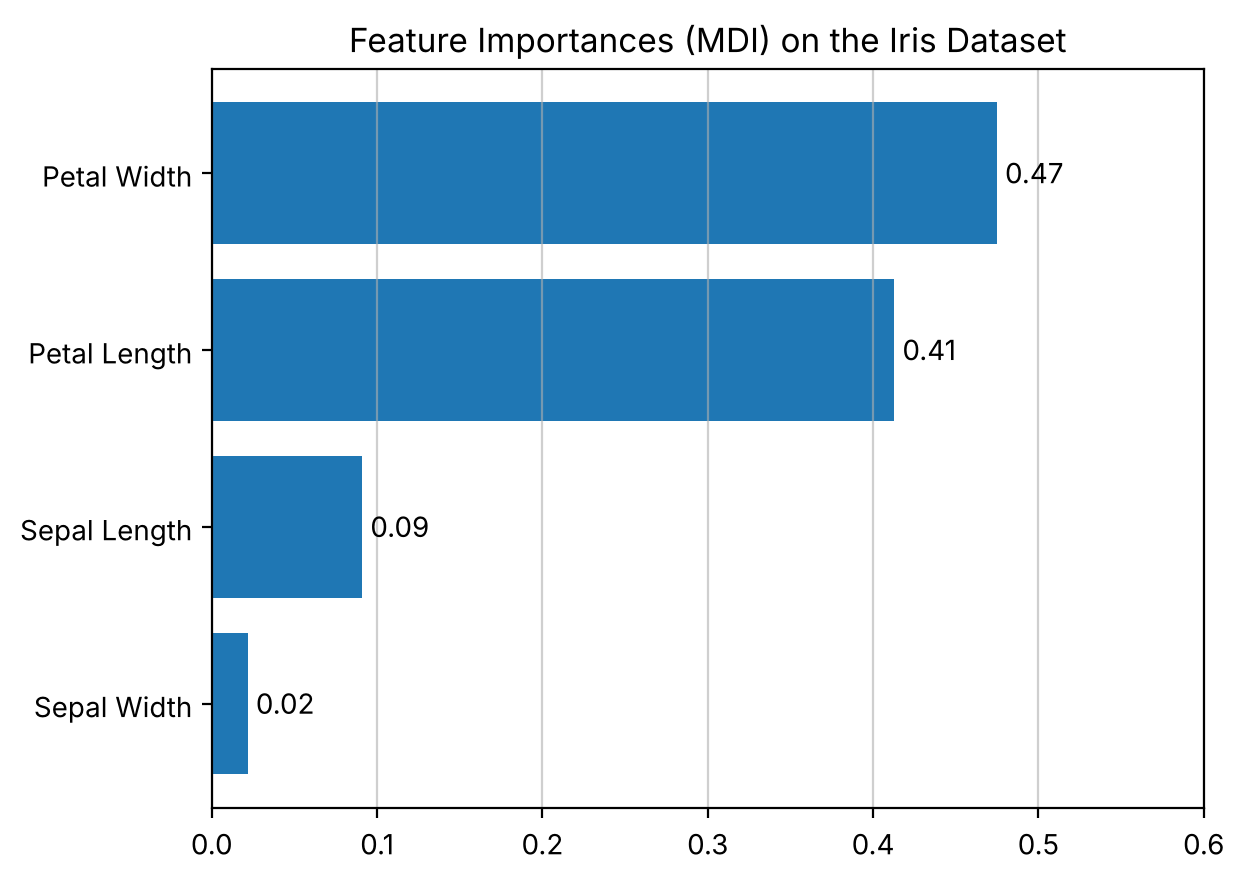

In [22]:
from sklearn.datasets import load_iris   # only used to load the data

iris = load_iris()
X_iris, y_iris = iris.data, iris.target
names_iris = ["Sepal Length", "Sepal Width", "Petal Length", "Petal Width"]

# a random forest with m = 2 ~ sqrt(4)
rf_iris = RandomForest(n_trees=300, max_features=2, seed=0).fit(X_iris, y_iris)
mdi_iris = rf_iris.feature_importances
perm_iris = permutation_importance(rf_iris, X_iris, y_iris, n_repeats=10)

print(f"OOB accuracy = {oob_accuracy(rf_iris, X_iris, y_iris):.3f}\n")
print(f"{'feature':<15} {'MDI':<8} {'Permutation':<12}")
print("-" * 35)
for j in np.argsort(-mdi_iris):
    print(f"{names_iris[j]:<15} {mdi_iris[j]:<8.3f} {perm_iris[j]:<12.3f}")

order = np.argsort(mdi_iris)
bars = plt.barh([names_iris[j] for j in order], mdi_iris[order])
plt.bar_label(bars, fmt="%.2f", padding=3)
plt.title("Feature Importances (MDI) on the Iris Dataset")
plt.xlim(0, 0.6)
plt.grid(True, axis="x", alpha=0.6)

MDI ranks the petal measurements far above the sepal ones, which lets us quickly identify the most influential features.

Notice that the permutation importances are all close to zero though. This is not a bug: Petal Length and Petal Width are very strongly correlated, so when we shuffle one of them, the trees can still use the other (and the forest has learnt to use both). Breaking one feature's link to the target barely hurts the score. So permutation importance measures how much the model **needs** a feature given the others, which can be small for a useful but redundant feature.

In [23]:
print("Correlation between Petal Length and Petal Width:", np.round(np.corrcoef(X_iris[:, 2], X_iris[:, 3])[0, 1], 3))

Correlation between Petal Length and Petal Width: 0.963


### MDI can credit pure noise
To see the bias of MDI, we go back to the $D = 10$ dataset from Section 5.4, where only $x_0,\dots,x_3$ carry signal and $x_4,\dots,x_9$ are pure noise.

Total MDI given to the 6 noise features         : 0.294
Total permutation score of the 6 noise features : 0.030


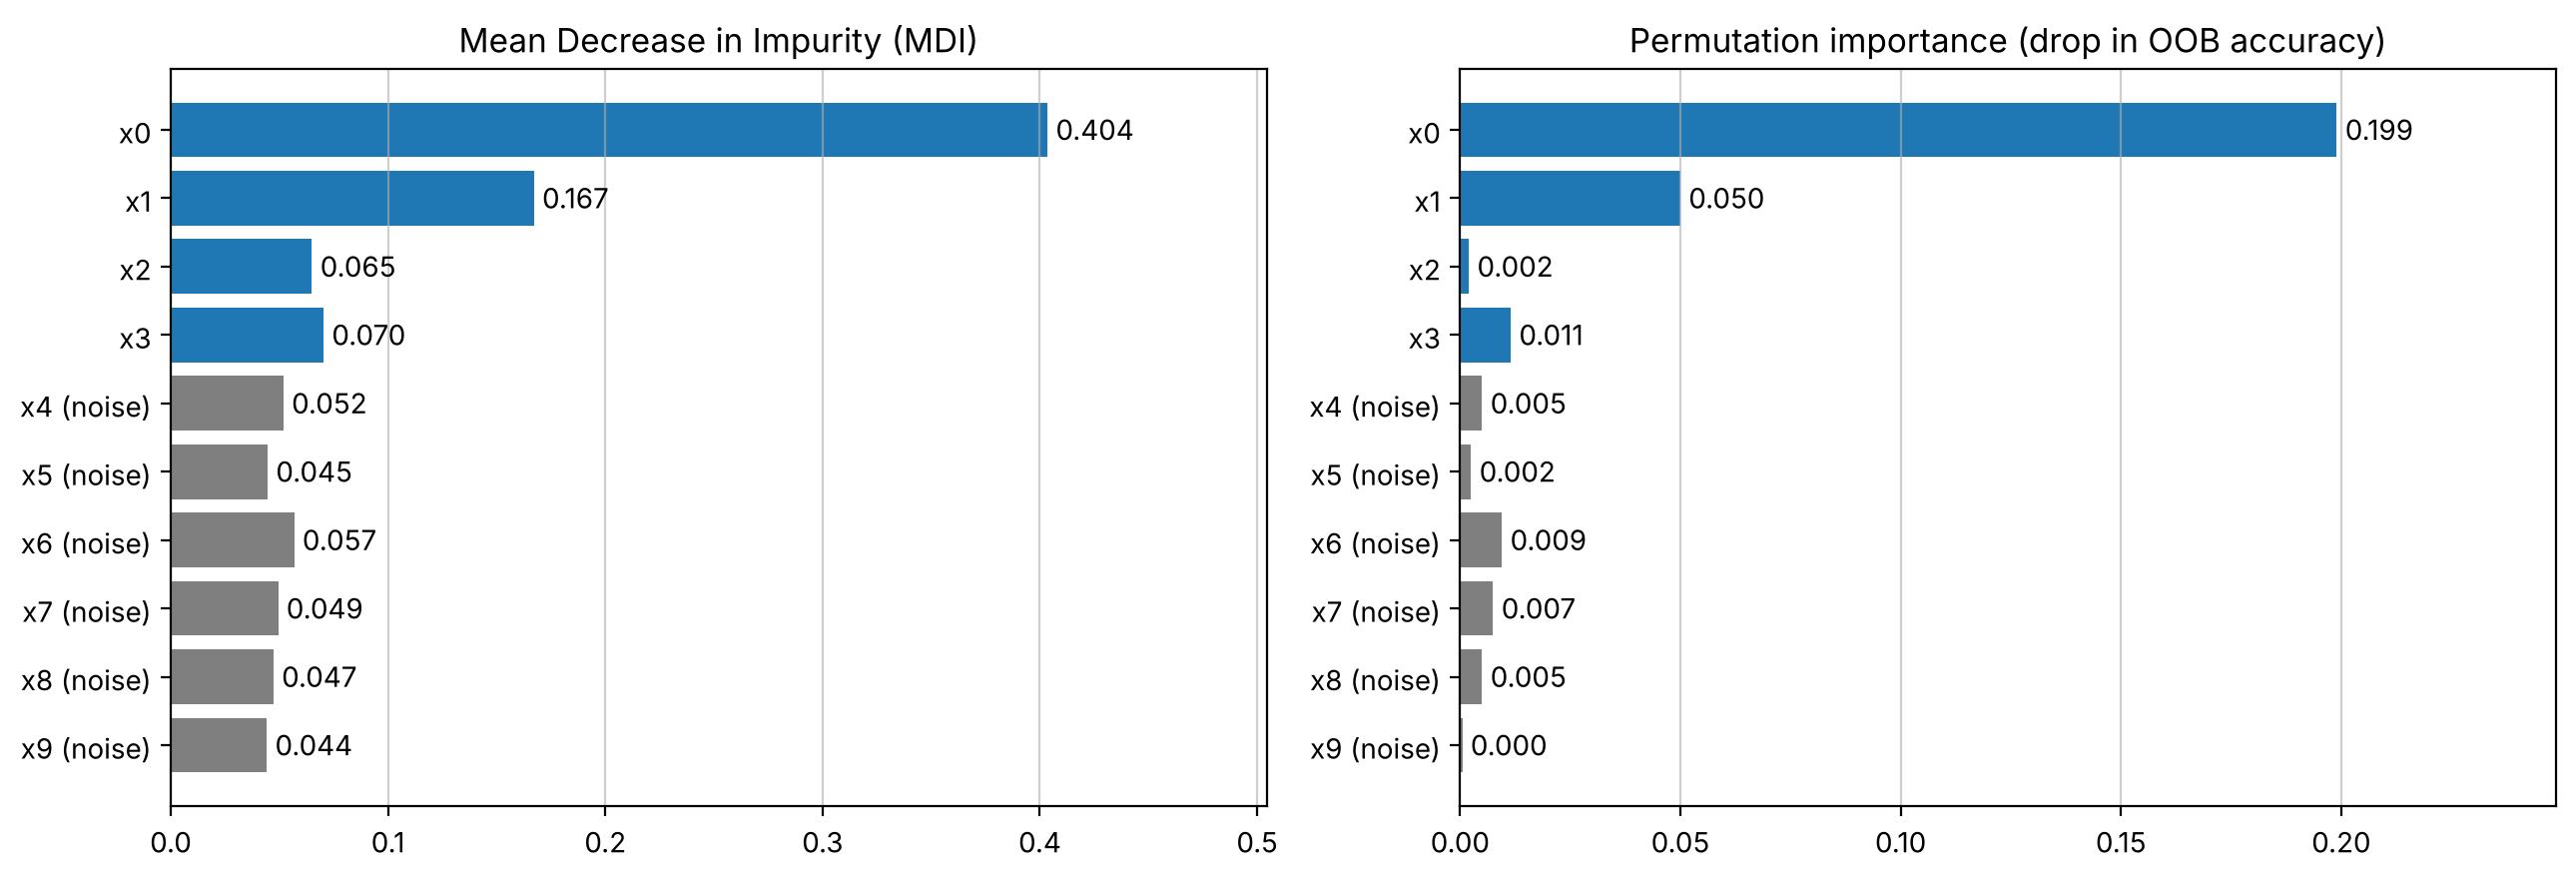

In [24]:
mdi_10 = rf10.feature_importances
perm_10 = permutation_importance(rf10, X10_tr, y10_tr, n_repeats=5)
names_10 = [f"x{j}" + (" (noise)" if j >= 4 else "") for j in range(10)]

print(f"Total MDI given to the 6 noise features         : {mdi_10[4:].sum():.3f}")
print(f"Total permutation score of the 6 noise features : {perm_10[4:].sum():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, scores, title in [(axes[0], mdi_10, "Mean Decrease in Impurity (MDI)"),
                          (axes[1], perm_10, "Permutation importance (drop in OOB accuracy)")]:
    colours = ["tab:blue" if j < 4 else "tab:gray" for j in range(10)]
    bars = ax.barh(names_10[::-1], scores[::-1], color=colours[::-1])
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_title(title)
    ax.set_xlim(0, scores.max()*1.25)
    ax.grid(True, axis="x", alpha=0.6)
plt.tight_layout()

MDI gives every noise feature (grey) a score of around 0.05, similar to the real but weaker features $x_2$ and $x_3$. This is because MDI is computed on the training data: deep trees can always find some split on a noise feature that purifies a node a little. Permutation importance is measured on the OOB data the trees never saw, so the noise features get roughly zero, and $x_0$ clearly stands out as the strongest feature.

# 7. Summary

* **kNN** classifies a point by a majority vote of its $k$ nearest training points. Small $k$ means high variance, large $k$ means high bias, and in high dimensions neighbourhoods stop being local (the **curse of dimensionality**).
* **Nonparametric models** don't assume a fixed functional form, and their complexity grows with the data: low bias but high variance.
* **Decision Trees** greedily split the feature space with axis-aligned cuts that maximise the reduction in impurity (Gini or Entropy). They are interpretable but very prone to overfitting.
* **Ensemble Learning** combines multiple models to produce a better one.
* **Bagging** reduces variance by training models on bootstrap samples and aggregating their predictions.
* **Random Forests** improve Bagging by subsampling features at each split, which decorrelates the trees.
* **Out-of-Bag (OOB) error** provides a fast and reliable estimate of test error, using the $\approx 37\%$ of points each tree didn't see.
* **Feature Importance** is attribution: $|w_j|$ for linear models, input gradients for differentiable ones, and MDI or permutation for forests, whose gradients vanish.